Fidelity F  Lambda    Empirical accuracy  Predicted (= F)
1.00        0.000     1.000               1.000
0.95        0.067     0.951               0.950
0.90        0.133     0.901               0.900
0.85        0.200     0.850               0.850
0.80        0.267     0.797               0.800
0.75        0.333     0.745               0.750
0.70        0.400     0.703               0.700
0.60        0.533     0.606               0.600
0.50        0.667     0.497               0.500
0.40        0.800     0.401               0.400


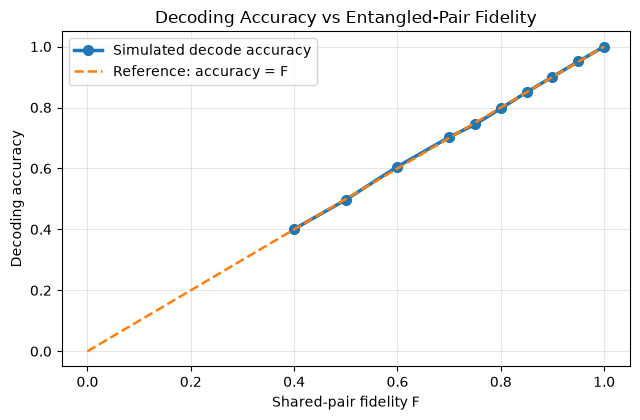


Per-message breakdown at F = 0.8:
Sent 00: {'00': 3236, '01': 247, '10': 256, '11': 261}
Sent 01: {'00': 252, '01': 3217, '10': 257, '11': 274}
Sent 10: {'00': 258, '01': 266, '10': 3207, '11': 269}
Sent 11: {'00': 263, '01': 259, '10': 257, '11': 3221}


In [7]:
import numpy as np
import matplotlib.pyplot as plt
from qiskit import QuantumCircuit
from qiskit_aer import AerSimulator
from qiskit_aer.noise import depolarizing_error
def encode_gate(qc, qubit, bits):
    """Alice encodes a 2-bit message."""
    b1, b0 = bits
    if b1 == 0 and b0 == 0:
        pass
    elif b1 == 0 and b0 == 1:
        qc.x(qubit)
    elif b1 == 1 and b0 == 0:
        qc.z(qubit)
    elif b1 == 1 and b0 == 1:
        qc.z(qubit)
        qc.x(qubit)
def fidelity_to_lambda(F):
    """Convert ideal Bell-state fidelity to a depolarizing parameter."""
    return (4 / 3) * (1 - F)
def superdense_noisy_pair(bits, lam):
    qc = QuantumCircuit(2, 2)
    # Create the Bell pair
    qc.h(0)
    qc.cx(0, 1)
    # Apply two-qubit depolarizing noise
    if lam > 0:
        qc.append(
            depolarizing_error(lam, 2).to_instruction(),
            [0, 1]
        )
    # Alice encodes her message
    encode_gate(qc, 0, bits)
    # Bob decodes the message
    qc.cx(0, 1)
    qc.h(0)
    # Map qubit 0 to classical bit 0, qubit 1 to classical bit 1
    qc.measure(0, 1)
    qc.measure(1, 0)
    return qc
sim = AerSimulator()
F_values = [
    1.0, 0.95, 0.9, 0.85, 0.8,
    0.75, 0.7, 0.6, 0.5, 0.4
]
accuracies = []
shots = 3000
for F in F_values:
    lam = fidelity_to_lambda(F)
    correct = 0
    total = 0
    for b1 in [0, 1]:
        for b0 in [0, 1]:
            msg = f"{b1}{b0}"
            counts = (
                sim.run(
                    superdense_noisy_pair((b1, b0), lam),
                    shots=shots
                )
                .result()
                .get_counts()
            )

            correct += counts.get(msg, 0)
            total += shots

    # Record one accuracy for each fidelity
    accuracies.append(correct / total)
print(
    f"{'Fidelity F':<12}"
    f"{'Lambda':<10}"
    f"{'Empirical accuracy':<20}"
    f"{'Predicted (= F)'}"
)

for F, acc in zip(F_values, accuracies):
    print(
        f"{F:<12.2f}"
        f"{fidelity_to_lambda(F):<10.3f}"
        f"{acc:<20.3f}"
        f"{F:.3f}"
    )

# Plot results
fig, ax = plt.subplots(figsize=(6.5, 4.3))
ax.plot(
    F_values, accuracies, 'o-',
    lw=2.5, ms=7,
    label='Simulated decode accuracy'
)
ax.plot(
    [0, 1], [0, 1], '--',
    lw=1.8,
    label='Reference: accuracy = F'
)
ax.set_xlabel('Shared-pair fidelity F')
ax.set_ylabel('Decoding accuracy')
ax.set_title('Decoding Accuracy vs Entangled-Pair Fidelity')
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()
# Per-message breakdown
F_demo = 0.8
lam = fidelity_to_lambda(F_demo)
print(f"\nPer-message breakdown at F = {F_demo}:")
for b1 in [0, 1]:
    for b0 in [0, 1]:
        msg = f"{b1}{b0}"
        counts = (
            sim.run(
                superdense_noisy_pair((b1, b0), lam),
                shots=4000
            )
            .result()
            .get_counts()
        )
        print(f"Sent {msg}: {dict(sorted(counts.items()))}")